In [ ]:
# Week 2 Clustering

In [25]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import io
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.cluster import AgglomerativeClustering
import os

Image type: <class 'numpy.ndarray'>
Image data type: uint8
Image shape: (2353, 4000, 3)


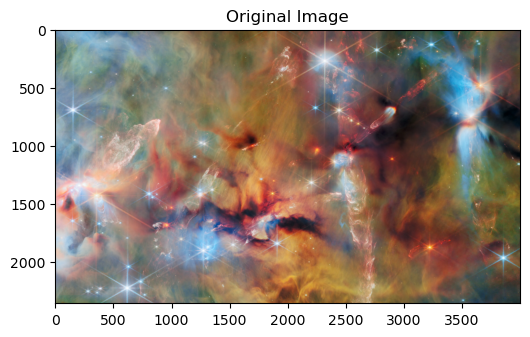

In [26]:
# Upload the Original Image
image_path = "/Users/roy/Desktop/ARU/Master/Machine learning in Imaging/Orion_A.webp"

img = io.imread(image_path)

print("Image type:", type(img))
print("Image data type:", img.dtype)
print("Image shape:", img.shape)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title("Original Image")
plt.axis("on")
plt.show()

In [27]:
# Prepared image of K-means. 

pixels = img.reshape(-1, 3)

print("Original image shape:", img.shape)
print("Pixel data shape:", pixels.shape)


Original image shape: (2353, 4000, 3)
Pixel data shape: (9412000, 3)


In [28]:
# K-means clustering with k = 2

kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)

labels_2 = kmeans_2.fit_predict(pixels)

prototypes_2 = kmeans_2.cluster_centers_

print("Cluster prototypes:")
print(prototypes_2)


Cluster prototypes:
[[155.65310964 146.66803643 138.05688503]
 [109.66199201  81.59545703  64.03214415]]


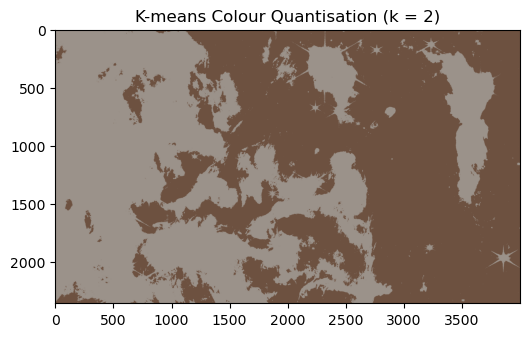

In [29]:
quantised_2 = prototypes_2[labels_2]

quantised_2 = np.clip(quantised_2, 0, 255).astype(np.uint8)

quantised_2 = quantised_2.reshape(img.shape)

plt.figure(figsize=(6, 6))
plt.imshow(quantised_2)
plt.title("K-means Colour Quantisation (k = 2)")
plt.axis("on")
plt.show()


In [30]:
# K-Means clustering with value k = 4

kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

labels_4 = kmeans_4.fit_predict(pixels)

prototypes_4 = kmeans_4.cluster_centers_

print("Cluster prototypes:")
print(prototypes_4)


Cluster prototypes:
[[158.913842   110.84043882  76.85174437]
 [ 86.16382651  66.56377946  56.56593743]
 [123.57574406 133.05692631 133.86942984]
 [179.24528343 178.67470136 181.76540738]]


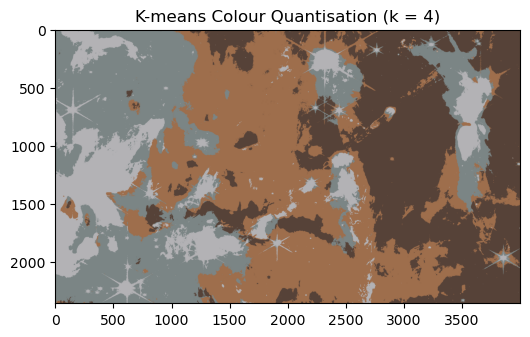

In [31]:
quantised_4 = prototypes_4[labels_4]

quantised_4 = np.clip(quantised_4, 0, 255).astype(np.uint8)

quantised_4 = quantised_4.reshape(img.shape)

plt.figure(figsize=(6, 6))
plt.imshow(quantised_4)
plt.title("K-means Colour Quantisation (k = 4)")
plt.axis("on")
plt.show()


Cropped image shape: (200, 200, 3)


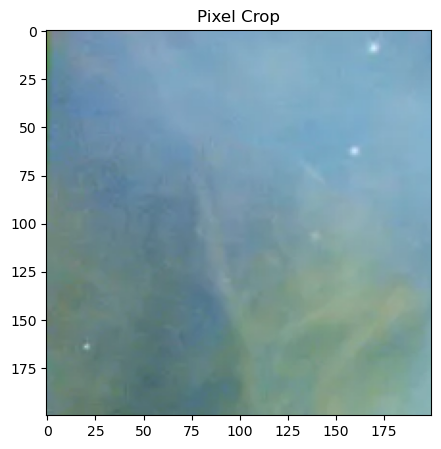

In [32]:
# Cropped Image 200 x 200 pixels

small_img = img[:200, :200]

print("Cropped image shape:", small_img.shape)

plt.figure(figsize=(5, 5))
plt.imshow(small_img)
plt.title("Pixel Crop")
plt.axis("on")
plt.show()


In [33]:
# Cropped image for agglomerative clustering

small_pixels = small_img.reshape(-1, 3)

print("Cropped pixel data shape:", small_pixels.shape)


Cropped pixel data shape: (40000, 3)


In [34]:
# Agglo Clustering with K = 2

agg_2 = AgglomerativeClustering(n_clusters=2)

agg_labels_2 = agg_2.fit_predict(small_pixels)

print("Number of clusters:", len(np.unique(agg_labels_2)))


Number of clusters: 2


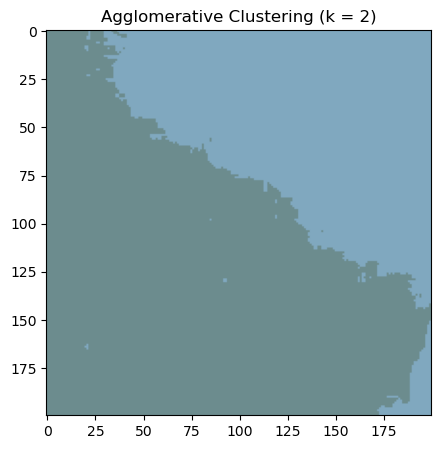

In [35]:
agg_prototypes_2 = np.array([
    small_pixels[agg_labels_2 == cluster].mean(axis=0)
    for cluster in np.unique(agg_labels_2)
])

agg_result_2 = agg_prototypes_2[agg_labels_2]

agg_result_2 = np.clip(agg_result_2, 0, 255).astype(np.uint8)

agg_result_2 = agg_result_2.reshape(small_img.shape)

plt.figure(figsize=(5, 5))
plt.imshow(agg_result_2)
plt.title("Agglomerative Clustering (k = 2)")
plt.axis("on")
plt.show()


In [36]:
# Agglo Clustering with K = 4

agg_6 = AgglomerativeClustering(n_clusters=6)

agg_labels_6 = agg_6.fit_predict(small_pixels)

print("Number of clusters:", len(np.unique(agg_labels_6)))


Number of clusters: 6


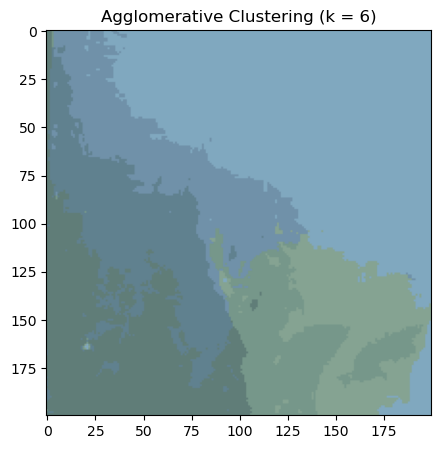

In [37]:
agg_prototypes_6 = np.array([
    small_pixels[agg_labels_6 == cluster].mean(axis=0)
    for cluster in np.unique(agg_labels_6)
])

agg_result_6 = agg_prototypes_6[agg_labels_6]

agg_result_6 = np.clip(agg_result_6, 0, 255).astype(np.uint8)

agg_result_6 = agg_result_6.reshape(small_img.shape)

plt.figure(figsize=(5, 5))
plt.imshow(agg_result_6)
plt.title("Agglomerative Clustering (k = 6)")
plt.axis("on")
plt.show()


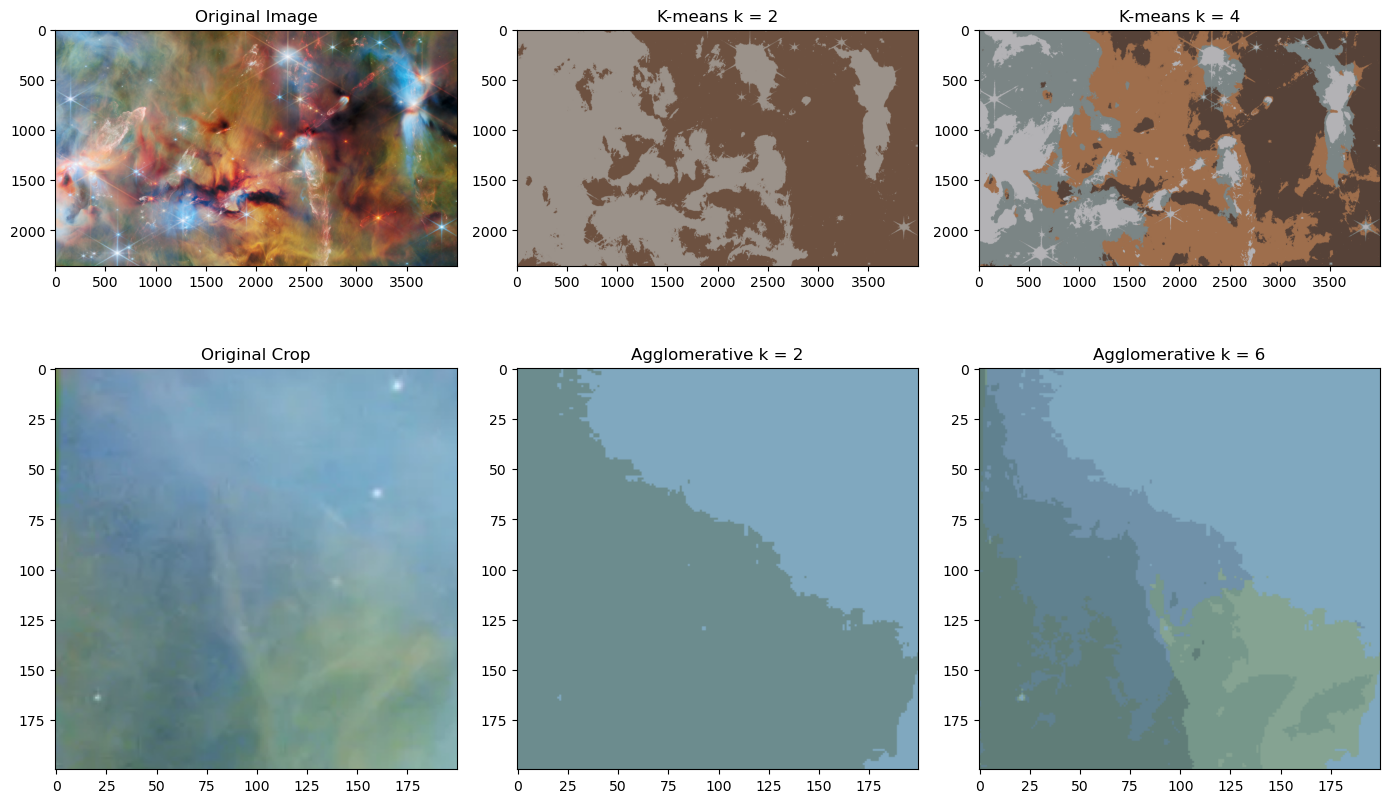

In [38]:
# All the Results
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes[0, 0].imshow(img)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(quantised_2)
axes[0, 1].set_title("K-means k = 2")

axes[0, 2].imshow(quantised_4)
axes[0, 2].set_title("K-means k = 4")

axes[1, 0].imshow(small_img)
axes[1, 0].set_title("Original Crop")

axes[1, 1].imshow(agg_result_2)
axes[1, 1].set_title("Agglomerative k = 2")

axes[1, 2].imshow(agg_result_6)
axes[1, 2].set_title("Agglomerative k = 6")

for ax in axes.ravel():
    ax.axis("on")

plt.tight_layout()
plt.show()
